In [1]:
# Standard library
import os
import sys
import json
import sqlite3
import asyncio
import logging
import hashlib
import operator

from pathlib import Path
from datetime import datetime, timezone
from typing import TypedDict, Annotated, Optional, Literal
from contextlib import asynccontextmanager

# Data processing
import numpy as np

# Environment variables
from dotenv import load_dotenv

# Data validation
from pydantic import BaseModel, Field

# LLM and LangChain
from langchain_groq import ChatGroq
from langchain_core.messages import ( BaseMessage,HumanMessage,
    AIMessage,SystemMessage)

# Embeddings for long-term memory retrieval
from sentence_transformers import SentenceTransformer

# LangGraph orchestration
from langgraph.graph import StateGraph, START, END
from langgraph.graph.message import add_messages

# LangSmith observability
from langsmith import Client

# MCP client
from mcp import ClientSession, StdioServerParameters
from mcp.client.stdio import stdio_client

# SQL validation
from sqlglot import parse, exp

print("All imports completed successfully.")

C:\Users\monis\AppData\Local\Programs\Python\Python313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


All imports completed successfully.


In [2]:
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

DATA_DIR = PROJECT_ROOT / "data"
MCP_DIR = PROJECT_ROOT / "mcp_servers"
AGENT_DIR = PROJECT_ROOT / "agents"

SCHEMA_SERVER_PATH = MCP_DIR / "schema" / "server.py"
WRITER_SERVER_PATH = MCP_DIR / "writer" / "server.py"
VERIFIER_SERVER_PATH = MCP_DIR / "verifier" / "server.py"

WRITER_AGENT_PATH = AGENT_DIR / "writer.py"
EVALUATOR_AGENT_PATH = AGENT_DIR / "evaluator.py"

DATABASE_PATH = DATA_DIR / "verisql_demo.db"
MEMORY_DATABASE_PATH = DATA_DIR / "verisql_memory.db"

EVALUATION_LOG_PATH = DATA_DIR / "evaluation_logs.jsonl"
WRITER_REPAIR_LOG_PATH = DATA_DIR / "writer_repair_logs.jsonl"

load_dotenv(PROJECT_ROOT / ".env")

GROQ_API_KEY = os.getenv("GROQ_API_KEY")
LANGCHAIN_API_KEY = os.getenv("LANGCHAIN_API_KEY")
LANGCHAIN_TRACING_V2 = os.getenv("LANGCHAIN_TRACING_V2", "false")
LANGCHAIN_PROJECT = os.getenv("LANGCHAIN_PROJECT", "VeriSQL")

EMBEDDING_MODEL_NAME = "sentence-transformers/all-MiniLM-L6-v2"
EMBEDDING_DIMENSION = 384
GROQ_MODEL = "openai/gpt-oss-20b"

DATA_DIR.mkdir(parents=True, exist_ok=True)

required_paths = {
    "Demo database": DATABASE_PATH,
    "Schema MCP": SCHEMA_SERVER_PATH,
    "Writer MCP": WRITER_SERVER_PATH,
    "Verifier MCP": VERIFIER_SERVER_PATH,
    "Writer agent": WRITER_AGENT_PATH,
    "Evaluator module": EVALUATOR_AGENT_PATH
}

print("Project root:", PROJECT_ROOT)

for component, path in required_paths.items():
    print(f"{component}: {'FOUND' if path.exists() else 'MISSING'}")

print("\nGroq API key:", bool(GROQ_API_KEY))
print("LangSmith API key:", bool(LANGCHAIN_API_KEY))
print("LangSmith tracing:", LANGCHAIN_TRACING_V2)
print("LangSmith project:", LANGCHAIN_PROJECT)
print("Memory database:", MEMORY_DATABASE_PATH)
print("Embedding model:", EMBEDDING_MODEL_NAME)

Project root: C:\Users\monis\OneDrive\Desktop\AI\Projects\SQL
Demo database: FOUND
Schema MCP: FOUND
Writer MCP: FOUND
Verifier MCP: FOUND
Writer agent: FOUND
Evaluator module: FOUND

Groq API key: True
LangSmith API key: True
LangSmith tracing: true
LangSmith project: VeriSQL
Memory database: C:\Users\monis\OneDrive\Desktop\AI\Projects\SQL\data\verisql_memory.db
Embedding model: sentence-transformers/all-MiniLM-L6-v2


In [3]:
with sqlite3.connect(MEMORY_DATABASE_PATH) as connection:
    connection.execute("""
        CREATE TABLE IF NOT EXISTS agent_memories (
            memory_id INTEGER PRIMARY KEY AUTOINCREMENT,
            session_id TEXT,
            question TEXT NOT NULL,
            sql_query TEXT NOT NULL,
            outcome TEXT NOT NULL,
            feedback TEXT,
            embedding BLOB NOT NULL,
            metadata TEXT,
            created_at TEXT DEFAULT CURRENT_TIMESTAMP
        )
    """)

    connection.execute("""
        CREATE INDEX IF NOT EXISTS idx_memory_outcome
        ON agent_memories(outcome)
    """)

    connection.execute("""
        CREATE INDEX IF NOT EXISTS idx_memory_session
        ON agent_memories(session_id)
    """)

    connection.commit()

print("Long-term memory database initialised.")

with sqlite3.connect(MEMORY_DATABASE_PATH) as connection:
    cursor = connection.execute("""
        SELECT name FROM sqlite_master
        WHERE type = 'table'
    """)
    print("Available tables:", [row[0] for row in cursor.fetchall()])

Long-term memory database initialised.
Available tables: ['agent_memories', 'sqlite_sequence']


In [4]:
embedding_model = SentenceTransformer(EMBEDDING_MODEL_NAME)

test_embedding = embedding_model.encode("Find employees working in Engineering.", normalize_embeddings=True)

print("Embedding model loaded successfully.")
print("Embedding shape:", test_embedding.shape)
print("Embedding dimension:", len(test_embedding))
print("Vector normalised:", np.isclose(np.linalg.norm(test_embedding), 1.0))

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 25502.56it/s]


Embedding model loaded successfully.
Embedding shape: (384,)
Embedding dimension: 384
Vector normalised: True


In [5]:
def store_memory(session_id, question, sql_query, outcome, feedback="", metadata=None):
    embedding = embedding_model.encode(
        question,
        normalize_embeddings=True
    ).astype(np.float32)

    metadata_json = json.dumps(metadata or {})

    with sqlite3.connect(MEMORY_DATABASE_PATH) as connection:
        connection.execute("""
            INSERT INTO agent_memories (
                session_id, question, sql_query, outcome,
                feedback, embedding, metadata
            )
            VALUES (?, ?, ?, ?, ?, ?, ?)
        """, (
            session_id,
            question,
            sql_query,
            outcome,
            feedback,
            embedding.tobytes(),
            metadata_json
        ))

    return {
        "stored": True,
        "embedding_dimension": len(embedding),
        "outcome": outcome
    }

print("Memory storage function created successfully.")

Memory storage function created successfully.


In [6]:
def retrieve_memories(question, top_k=3, min_similarity=0.35):
    query_embedding = embedding_model.encode(
        question,
        normalize_embeddings=True
    ).astype(np.float32)

    with sqlite3.connect(MEMORY_DATABASE_PATH) as connection:
        connection.row_factory = sqlite3.Row
        records = connection.execute("""
            SELECT memory_id, session_id, question, sql_query,
                   outcome, feedback, embedding, metadata, created_at
            FROM agent_memories
        """).fetchall()

    memories = []

    for record in records:
        stored_embedding = np.frombuffer(
            record["embedding"],
            dtype=np.float32
        )

        if stored_embedding.shape != query_embedding.shape:
            continue

        similarity = float(np.dot(query_embedding, stored_embedding))

        if similarity >= min_similarity:
            memories.append({
                "memory_id": record["memory_id"],
                "session_id": record["session_id"],
                "question": record["question"],
                "sql_query": record["sql_query"],
                "outcome": record["outcome"],
                "feedback": record["feedback"],
                "metadata": json.loads(record["metadata"] or "{}"),
                "similarity": round(similarity, 4),
                "created_at": record["created_at"]
            })

    memories.sort(key=lambda item: item["similarity"], reverse=True)

    return memories[:top_k]


print("Semantic memory retrieval function created successfully.")

Semantic memory retrieval function created successfully.


In [7]:
test_memories = [
    {
        "session_id": "session_001",
        "question": "Find employees working in Engineering.",
        "sql_query": """
            SELECT e.employee_name
            FROM employees e
            JOIN departments d
            ON e.department_id = d.department_id
            WHERE d.department_name = 'Engineering';
        """,
        "outcome": "accepted",
        "feedback": "Correct department JOIN and filter."
    },
    {
        "session_id": "session_002",
        "question": "Find employees assigned to the AI Platform project.",
        "sql_query": """
            SELECT e.employee_name
            FROM employees e
            JOIN employee_projects ep ON e.employee_id = ep.employee_id
            JOIN projects p ON ep.project_id = p.project_id
            WHERE p.project_name = 'AI Platform';
        """,
        "outcome": "accepted",
        "feedback": "Correct JOIN across three tables."
    }
]

with sqlite3.connect(MEMORY_DATABASE_PATH) as connection:
    connection.execute("""
        DELETE FROM agent_memories
        WHERE session_id IN ('session_001', 'session_002')
    """)

for memory in test_memories:
    store_memory(**memory)

retrieved_memories = retrieve_memories(
    question="Show me the people belonging to the Engineering department.",
    top_k=3
)

print("Retrieved memories:", len(retrieved_memories))

for memory in retrieved_memories:
    print("\nQuestion:", memory["question"])
    print("Outcome:", memory["outcome"])
    print("Similarity:", memory["similarity"])
    print("Original session:", memory["session_id"])

Retrieved memories: 1

Question: Find employees working in Engineering.
Outcome: accepted
Similarity: 0.6258
Original session: session_001


In [8]:
def format_memory_context(memories):
    if not memories:
        return "No relevant previous experiences found."

    context = []

    for index, memory in enumerate(memories, start=1):
        context.append(
            f"Memory {index}:\n"
            f"Previous question: {memory['question']}\n"
            f"Previous SQL: {memory['sql_query']}\n"
            f"Outcome: {memory['outcome']}\n"
            f"Feedback: {memory['feedback']}\n"
            f"Similarity: {memory['similarity']}"
        )

    return "\n\n".join(context)


memory_context = format_memory_context(retrieved_memories)

print(memory_context)

Memory 1:
Previous question: Find employees working in Engineering.
Previous SQL: 
            SELECT e.employee_name
            FROM employees e
            JOIN departments d
            ON e.department_id = d.department_id
            WHERE d.department_name = 'Engineering';
        
Outcome: accepted
Feedback: Correct department JOIN and filter.
Similarity: 0.6258


In [9]:
def filter_memories(memories, top_k=3, min_similarity=0.35):
    filtered = [
        memory for memory in memories
        if memory["similarity"] >= min_similarity
    ]

    filtered.sort(
        key=lambda memory: (
            memory["outcome"] == "accepted",
            memory["similarity"]
        ),
        reverse=True
    )

    return filtered[:top_k]


def build_agent_memory_context(memories):
    if not memories:
        return "No relevant previous experiences available."

    accepted = [
        memory for memory in memories
        if memory["outcome"] == "accepted"
    ]

    rejected = [
        memory for memory in memories
        if memory["outcome"] != "accepted"
    ]

    sections = []

    if accepted:
        sections.append("PREVIOUS SUCCESSFUL EXPERIENCES:")
        for memory in accepted:
            sections.append(
                f"Question: {memory['question']}\n"
                f"SQL pattern: {memory['sql_query']}\n"
                f"Feedback: {memory['feedback']}"
            )

    if rejected:
        sections.append("\nPREVIOUS FAILED EXPERIENCES — USE AS WARNINGS:")
        for memory in rejected:
            sections.append(
                f"Question: {memory['question']}\n"
                f"Failed SQL: {memory['sql_query']}\n"
                f"Failure feedback: {memory['feedback']}"
            )

    return "\n\n".join(sections)


filtered_memories = filter_memories(retrieved_memories)
agent_memory_context = build_agent_memory_context(filtered_memories)

print(agent_memory_context)

PREVIOUS SUCCESSFUL EXPERIENCES:

Question: Find employees working in Engineering.
SQL pattern: 
            SELECT e.employee_name
            FROM employees e
            JOIN departments d
            ON e.department_id = d.department_id
            WHERE d.department_name = 'Engineering';
        
Feedback: Correct department JOIN and filter.


In [10]:
async def generate_sql_with_memory(question, db_id="verisql_demo", top_k=3):
    memories = retrieve_memories(question, top_k=top_k)
    memories = filter_memories(memories, top_k=top_k)
    memory_context = build_agent_memory_context(memories)

    enriched_question = (
        f"Current user question: {question}\n\n"
        f"Previous experiences (reference only):\n{memory_context}\n\n"
        "Generate SQL for the current question only. "
        "Use the actual database schema as the source of truth. "
        "Do not copy previous SQL without validating its relevance."
    )

    server_params = StdioServerParameters(
        command=sys.executable,
        args=[str(WRITER_SERVER_PATH)],
        cwd=str(PROJECT_ROOT),
        env={**os.environ, "PYTHONPATH": str(PROJECT_ROOT)}
    )

    with open(DATA_DIR / "writer_memory_mcp.log", "a", encoding="utf-8") as errlog:
        async with stdio_client(server_params, errlog=errlog) as (read, write):
            async with ClientSession(read, write) as session:
                await session.initialize()
                response = await session.call_tool(
                    "generate_sql",
                    {"question": enriched_question, "db_id": db_id}
                )

    return {
        "question": question,
        "memory_count": len(memories),
        "memory_context": memory_context,
        "writer_response": response.model_dump()
    }


print("Memory-aware Writer MCP function created successfully.")

Memory-aware Writer MCP function created successfully.


In [11]:
class VeriSQLState(TypedDict):
    session_id: str
    question: str
    db_id: str
    messages: Annotated[list[BaseMessage], add_messages]
    retrieved_memories: list[dict]
    memory_context: str
    sql_query: str
    validation_report: dict
    execution_results: dict
    evaluation: dict
    feedback: str
    repair_count: int
    final_response: str
    workflow_history: list[dict]


print("VeriSQL LangGraph state defined successfully.")
print("State fields:", list(VeriSQLState.__annotations__.keys()))

VeriSQL LangGraph state defined successfully.
State fields: ['session_id', 'question', 'db_id', 'messages', 'retrieved_memories', 'memory_context', 'sql_query', 'validation_report', 'execution_results', 'evaluation', 'feedback', 'repair_count', 'final_response', 'workflow_history']


In [12]:
def memory_retrieval_node(state: VeriSQLState) -> dict:
    memories = retrieve_memories(state["question"], top_k=3)
    memories = filter_memories(memories, top_k=3)
    memory_context = build_agent_memory_context(memories)

    return {
        "retrieved_memories": memories,
        "memory_context": memory_context,
        "workflow_history": state.get("workflow_history", []) + [{
            "step": "memory_retrieval",
            "memories_retrieved": len(memories)
        }]
    }


print("Memory retrieval node created successfully.")

Memory retrieval node created successfully.


In [13]:
async def writer_node(state: VeriSQLState) -> dict:
    writer_result = await generate_sql_with_memory(
        question=state["question"],
        db_id=state.get("db_id", "verisql_demo"),
        top_k=3
    )

    return {
        "writer_response": writer_result["writer_response"],
        "workflow_history": state.get("workflow_history", []) + [{
            "step": "writer_agent",
            "memories_used": writer_result["memory_count"]
        }]
    }


print("Writer Agent node created successfully.")

Writer Agent node created successfully.


In [14]:
def extract_generated_sql(writer_response):
    for item in writer_response.get("content", []):
        text_content = item.get("text", "")

        try:
            result = json.loads(text_content)
            if isinstance(result, dict) and result.get("sql_query"):
                return result["sql_query"]
        except (json.JSONDecodeError, TypeError):
            if "SELECT" in text_content.upper():
                return text_content

    raise ValueError("Writer MCP did not return a valid SQL query.")


async def evaluator_node(state: VeriSQLState) -> dict:
    sql_query = extract_generated_sql(state["writer_response"])

    evaluation = await evaluate_sql(
        question=state["question"],
        sql_query=sql_query,
        db_id=state.get("db_id", "verisql_demo")
    )

    evaluation_data = evaluation.model_dump()

    return {
        "sql_query": sql_query,
        "evaluation": evaluation_data,
        "feedback": evaluation_data.get("feedback", ""),
        "workflow_history": state.get("workflow_history", []) + [{
            "step": "evaluator_agent",
            "decision": evaluation_data["decision"]
        }]
    }


print("Evaluator Agent node created successfully.")

Evaluator Agent node created successfully.


In [15]:
def route_after_evaluation(state: VeriSQLState) -> Literal["accept", "repair", "stop"]:
    evaluation = state.get("evaluation", {})
    repair_count = state.get("repair_count", 0)

    if evaluation.get("decision") == "accept":
        return "accept"

    if not evaluation.get("safety_valid", False):
        return "stop"

    if repair_count >= 3:
        return "stop"

    return "repair"


print("Conditional routing function created successfully.")

Conditional routing function created successfully.


In [16]:
async def repair_node(state: VeriSQLState) -> dict:
    server_params = StdioServerParameters(
        command=sys.executable,
        args=[str(WRITER_SERVER_PATH)],
        cwd=str(PROJECT_ROOT),
        env={**os.environ, "PYTHONPATH": str(PROJECT_ROOT)}
    )

    with open(DATA_DIR / "writer_repair_mcp.log", "a", encoding="utf-8") as errlog:
        async with stdio_client(server_params, errlog=errlog) as (read, write):
            async with ClientSession(read, write) as session:
                await session.initialize()
                response = await session.call_tool(
                    "repair_sql",
                    {
                        "question": state["question"],
                        "previous_sql": state["sql_query"],
                        "evaluator_feedback": state["feedback"],
                        "db_id": state.get("db_id", "verisql_demo")
                    }
                )

    return {
        "writer_response": response.model_dump(),
        "repair_count": state.get("repair_count", 0) + 1,
        "workflow_history": state.get("workflow_history", []) + [{
            "step": "sql_repair",
            "repair_attempt": state.get("repair_count", 0) + 1
        }]
    }


print("SQL repair node created successfully.")

SQL repair node created successfully.


In [17]:
def final_response_node(state: VeriSQLState) -> dict:
    evaluation = state.get("evaluation", {})
    decision = evaluation.get("decision", "reject")
    sql_query = state.get("sql_query", "")

    if decision == "accept":
        final_response = (
            "SQL query generated and verified successfully.\n\n"
            f"SQL:\n{sql_query}"
        )
    else:
        final_response = (
            "SQL query could not be verified.\n\n"
            f"Reason: {state.get('feedback', 'Maximum repair attempts reached or safety validation failed.')}"
        )

    return {
        "final_response": final_response,
        "workflow_history": state.get("workflow_history", []) + [{
            "step": "final_response",
            "decision": decision,
            "repair_count": state.get("repair_count", 0)
        }]
    }


print("Final response node created successfully.")

Final response node created successfully.


In [18]:
def memory_storage_node(state: VeriSQLState) -> dict:
    evaluation = state.get("evaluation", {})
    outcome = evaluation.get("decision", "reject")

    sql_query = (
        state.get("sql_query", "")
        if evaluation.get("safety_valid", False)
        else "[SQL withheld due to safety violation]"
    )

    result = store_memory(
        session_id=state["session_id"],
        question=state["question"],
        sql_query=sql_query,
        outcome=outcome,
        feedback=state.get("feedback", ""),
        metadata={
            "repair_count": state.get("repair_count", 0),
            "semantic_correct": evaluation.get("semantic_correct", False),
            "execution_success": evaluation.get("execution_success", False),
            "database_id": state.get("db_id", "verisql_demo")
        }
    )

    return {
        "workflow_history": state.get("workflow_history", []) + [{
            "step": "memory_storage",
            "stored": result["stored"],
            "outcome": outcome
        }]
    }


print("Long-term memory storage node created successfully.")

Long-term memory storage node created successfully.


In [19]:
class VeriSQLState(TypedDict):
    session_id: str
    question: str
    db_id: str
    messages: Annotated[list[BaseMessage], add_messages]
    retrieved_memories: list[dict]
    memory_context: str
    writer_response: dict
    sql_query: str
    validation_report: dict
    execution_results: dict
    evaluation: dict
    feedback: str
    repair_count: int
    final_response: str
    workflow_history: list[dict]


workflow = StateGraph(VeriSQLState)

workflow.add_node("memory_retrieval", memory_retrieval_node)
workflow.add_node("writer", writer_node)
workflow.add_node("evaluator", evaluator_node)
workflow.add_node("repair", repair_node)
workflow.add_node("final_response", final_response_node)
workflow.add_node("memory_storage", memory_storage_node)

workflow.add_edge(START, "memory_retrieval")
workflow.add_edge("memory_retrieval", "writer")
workflow.add_edge("writer", "evaluator")

workflow.add_conditional_edges(
    "evaluator",
    route_after_evaluation,
    {
        "accept": "final_response",
        "repair": "repair",
        "stop": "final_response"
    }
)

workflow.add_edge("repair", "evaluator")
workflow.add_edge("final_response", "memory_storage")
workflow.add_edge("memory_storage", END)

print("VeriSQL LangGraph workflow constructed successfully.")
print("Nodes:", list(workflow.nodes.keys()))

VeriSQL LangGraph workflow constructed successfully.
Nodes: ['memory_retrieval', 'writer', 'evaluator', 'repair', 'final_response', 'memory_storage']


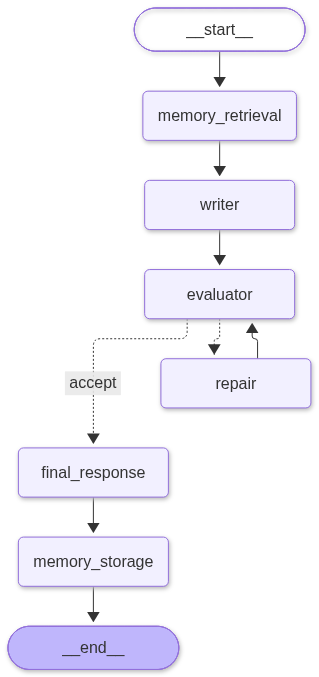

In [22]:
from IPython.display import display, Image

compiled_workflow = workflow.compile()

flowchart_image = compiled_workflow.get_graph().draw_mermaid_png()

display(Image(flowchart_image))

In [23]:
os.environ["LANGCHAIN_TRACING_V2"] = "true"
os.environ["LANGCHAIN_API_KEY"] = LANGCHAIN_API_KEY
os.environ["LANGCHAIN_PROJECT"] = LANGCHAIN_PROJECT

langsmith_client = Client(api_key=LANGCHAIN_API_KEY)

print("LangSmith client initialised.")
print("Tracing enabled:", os.getenv("LANGCHAIN_TRACING_V2"))
print("Project:", LANGCHAIN_PROJECT)

LangSmith client initialised.
Tracing enabled: true
Project: VeriSQL


In [30]:
load_dotenv(PROJECT_ROOT / ".env", override=True)

LANGSMITH_API_KEY = os.getenv("LANGSMITH_API_KEY")
LANGSMITH_TRACING = os.getenv("LANGSMITH_TRACING", "false")
LANGSMITH_PROJECT = os.getenv("LANGSMITH_PROJECT", "VeriSQL")
LANGSMITH_ENDPOINT = os.getenv(
    "LANGSMITH_ENDPOINT",
    "https://api.smith.langchain.com"
)

langsmith_client = Client(
    api_key=LANGSMITH_API_KEY,
    api_url=LANGSMITH_ENDPOINT
)

print("LangSmith key loaded:", bool(LANGSMITH_API_KEY))
print("Tracing:", LANGSMITH_TRACING)
print("Project:", LANGSMITH_PROJECT)

LangSmith key loaded: True
Tracing: true
Project: VeriSQL


In [31]:
import requests

response = requests.get(
    f"{LANGSMITH_ENDPOINT}/info",
    headers={"x-api-key": LANGSMITH_API_KEY},
    timeout=15
)

print("Status:", response.status_code)
print("Response:", response.text[:500])

Status: 200
Response: {"engine_github_web_base_url":"https://github.com","version":"0.19.3","git_sha":"448a451ba349165f8656de27edbbb8b9f2dfc42c","instance_flags":{"access_policy_catalog_supported":true,"agent_list_count_supported":true,"agent_search_supported":true,"agent_server_rename":true,"alert_action_suspension_supported":true,"alert_webhook_default_body_fields_supported":true,"allowed_longlived_ttl_days":[30,60,90,120,150,180,240,300,365,400],"blob_storage_enabled":true,"blob_storage_engine":"gcs","ch_ingestion


In [33]:
import requests

endpoints = {
    "US": "https://api.smith.langchain.com",
    "EU": "https://eu.api.smith.langchain.com",
    "APAC": "https://apac.api.smith.langchain.com"
}

for region, endpoint in endpoints.items():
    try:
        response = requests.get(
            f"{endpoint}/sessions",
            headers={"x-api-key": LANGSMITH_API_KEY},
            params={"limit": 1, "offset": 0},
            timeout=15
        )
        print(f"{region}: HTTP {response.status_code}")
    except requests.RequestException as error:
        print(f"{region}: {error}")

US: HTTP 403
EU: HTTP 403
APAC: HTTP 403


In [34]:
key = LANGSMITH_API_KEY.strip()

if key.startswith("lsv2_pt_"):
    key_type = "Personal Access Token"
elif key.startswith("lsv2_sk_"):
    key_type = "Service Key"
elif key.startswith("lsv2_tr_"):
    key_type = "Tracing Key"
else:
    key_type = "Unknown or legacy key"

print("API key type:", key_type)
print("Key loaded:", bool(key))
print("Key length:", len(key))

API key type: Personal Access Token
Key loaded: True
Key length: 51


In [35]:
os.environ["LANGSMITH_TRACING"] = "true"
os.environ["LANGSMITH_API_KEY"] = LANGSMITH_API_KEY
os.environ["LANGSMITH_PROJECT"] = "VeriSQL"
os.environ["LANGSMITH_ENDPOINT"] = LANGSMITH_ENDPOINT

print("LangSmith tracing configuration loaded.")
print("Project:", LANGSMITH_PROJECT)
print("API key available:", bool(LANGSMITH_API_KEY))

LangSmith tracing configuration loaded.
Project: VeriSQL
API key available: True


In [38]:
from langgraph.checkpoint.sqlite.aio import AsyncSqliteSaver

print("Async SQLite checkpointer imported successfully.")

Async SQLite checkpointer imported successfully.


In [39]:
async def run_verisql_workflow(question, session_id, db_id="verisql_demo"):
    async with AsyncSqliteSaver.from_conn_string(str(MEMORY_DATABASE_PATH)) as checkpointer:
        compiled_graph = workflow.compile(checkpointer=checkpointer)

        config = {
            "configurable": {
                "thread_id": session_id
            }
        }

        initial_state = {
            "session_id": session_id,
            "question": question,
            "db_id": db_id,
            "messages": [HumanMessage(content=question)],
            "retrieved_memories": [],
            "memory_context": "",
            "writer_response": {},
            "sql_query": "",
            "validation_report": {},
            "execution_results": {},
            "evaluation": {},
            "feedback": "",
            "repair_count": 0,
            "final_response": "",
            "workflow_history": []
        }

        result = await compiled_graph.ainvoke(initial_state, config=config)
        return result

print("Persistent LangGraph execution function defined.")

Persistent LangGraph execution function defined.


In [40]:
evaluator_source = EVALUATOR_AGENT_PATH.read_text(encoding="utf-8")
print(evaluator_source)


import sqlite3
from pathlib import Path

from sqlglot import parse, exp


PROJECT_ROOT = Path(__file__).resolve().parents[1]
DATABASE_PATH = PROJECT_ROOT / "data" / "verisql_demo.db"


def validate_sql_syntax(sql_query: str) -> dict:
    """Validate SQL syntax and ensure exactly one query is provided."""

    try:
        parsed_queries = parse(sql_query, read="sqlite")

        if len(parsed_queries) != 1 or parsed_queries[0] is None:
            return {"valid": False, "error": "Only one SQL statement is allowed."}

        if not isinstance(parsed_queries[0], exp.Query):
            return {"valid": False, "error": "Only SELECT queries are allowed."}

        return {"valid": True, "error": None}

    except Exception as error:
        return {"valid": False, "error": str(error)}


def validate_sql_safety(sql_query: str) -> dict:
    """Reject modifying operations and access to sensitive columns."""

    syntax_result = validate_sql_syntax(sql_query)

    if not syntax_result["vali

In [41]:
sys.path.insert(0, str(PROJECT_ROOT))

from agents.evaluator import (
    validate_sql_syntax,
    validate_sql_safety,
    validate_sql_schema,
    validate_sql_execution
)

print("Existing evaluator functions imported successfully.")

Existing evaluator functions imported successfully.


In [42]:
def evaluator_node(state: VeriSQLState) -> dict:
    sql_query = extract_generated_sql(state["writer_response"])

    syntax_result = validate_sql_syntax(sql_query)

    if syntax_result["valid"]:
        safety_result = validate_sql_safety(sql_query)
    else:
        safety_result = {"valid": False, "error": syntax_result["error"]}

    if safety_result["valid"]:
        schema_result = validate_sql_schema(sql_query)
    else:
        schema_result = {"valid": False, "error": safety_result["error"]}

    if schema_result["valid"]:
        execution_result = validate_sql_execution(sql_query)
    else:
        execution_result = {
            "valid": False,
            "error": schema_result["error"],
            "columns": [],
            "rows": []
        }

    accepted = all([
        syntax_result["valid"],
        safety_result["valid"],
        schema_result["valid"],
        execution_result["valid"]
    ])

    feedback = (
        "SQL passed all deterministic validation checks."
        if accepted
        else next(
            result["error"]
            for result in [
                syntax_result,
                safety_result,
                schema_result,
                execution_result
            ]
            if not result["valid"]
        )
    )

    evaluation = {
        "accepted": accepted,
        "decision": "accept" if accepted else "repair",
        "safety_valid": safety_result["valid"],
        "syntax": syntax_result,
        "safety": safety_result,
        "schema": schema_result,
        "execution": execution_result
    }

    return {
        "sql_query": sql_query,
        "evaluation": evaluation,
        "validation_report": evaluation,
        "execution_results": execution_result,
        "feedback": feedback,
        "workflow_history": state.get("workflow_history", []) + [{
            "node": "evaluator",
            "decision": evaluation["decision"],
            "feedback": feedback
        }]
    }

print("Deterministic evaluator node defined successfully.")

Deterministic evaluator node defined successfully.


In [43]:
def route_after_evaluation(state: VeriSQLState) -> Literal["accept", "repair", "stop"]:
    evaluation = state.get("evaluation", {})
    repair_count = state.get("repair_count", 0)

    syntax_valid = evaluation.get("syntax", {}).get("valid", False)
    safety_valid = evaluation.get("safety", {}).get("valid", False)

    if syntax_valid and not safety_valid:
        return "stop"

    if evaluation.get("accepted", False):
        return "accept"

    if repair_count >= 3:
        return "stop"

    return "repair"


print("Evaluator routing function defined successfully.")

Evaluator routing function defined successfully.


In [44]:
workflow = StateGraph(VeriSQLState)

workflow.add_node("memory_retrieval", memory_retrieval_node)
workflow.add_node("writer", writer_node)
workflow.add_node("evaluator", evaluator_node)
workflow.add_node("repair", repair_node)
workflow.add_node("final_response", final_response_node)
workflow.add_node("memory_storage", memory_storage_node)

workflow.add_edge(START, "memory_retrieval")
workflow.add_edge("memory_retrieval", "writer")
workflow.add_edge("writer", "evaluator")

workflow.add_conditional_edges(
    "evaluator",
    route_after_evaluation,
    {
        "accept": "final_response",
        "repair": "repair",
        "stop": "final_response"
    }
)

workflow.add_edge("repair", "evaluator")
workflow.add_edge("final_response", "memory_storage")
workflow.add_edge("memory_storage", END)

print("LangGraph workflow rebuilt successfully.")
print("Nodes:", list(workflow.nodes.keys()))

LangGraph workflow rebuilt successfully.
Nodes: ['memory_retrieval', 'writer', 'evaluator', 'repair', 'final_response', 'memory_storage']


In [45]:
compiled_workflow = workflow.compile()

print("Workflow compiled successfully.")
print("Graph nodes:", list(compiled_workflow.get_graph().nodes.keys()))
print("\nWorkflow structure:")
print(compiled_workflow.get_graph().draw_mermaid())

Workflow compiled successfully.
Graph nodes: ['__start__', 'memory_retrieval', 'writer', 'evaluator', 'repair', 'final_response', 'memory_storage', '__end__']

Workflow structure:
---
config:
  flowchart:
    curve: linear
---
graph TD;
	__start__([<p>__start__</p>]):::first
	memory_retrieval(memory_retrieval)
	writer(writer)
	evaluator(evaluator)
	repair(repair)
	final_response(final_response)
	memory_storage(memory_storage)
	__end__([<p>__end__</p>]):::last
	__start__ --> memory_retrieval;
	evaluator -. &nbsp;accept&nbsp; .-> final_response;
	evaluator -.-> repair;
	final_response --> memory_storage;
	memory_retrieval --> writer;
	repair --> evaluator;
	writer --> evaluator;
	memory_storage --> __end__;
	classDef default fill:#f2f0ff,line-height:1.2
	classDef first fill-opacity:0
	classDef last fill:#bfb6fc



In [46]:
compiled_workflow = workflow.compile()

print("VeriSQL workflow is compiled and ready for execution.")

VeriSQL workflow is compiled and ready for execution.


In [48]:
os.environ["LANGSMITH_TRACING"] = "false"
os.environ["LANGCHAIN_TRACING_V2"] = "false"

print("LangSmith tracing disabled.")
print("Local SQLite memory remains enabled.")
print("Writer and Verifier MCP integration remains unchanged.")

LangSmith tracing disabled.
Local SQLite memory remains enabled.
Writer and Verifier MCP integration remains unchanged.


In [49]:
session_id = "verisql_session_001"
question = "List the names and salaries of employees working in the Engineering department."

result = await run_verisql_workflow(
    question=question,
    session_id=session_id
)

print("Final response:")
print(result.get("final_response", "No final response generated."))

print("\nGenerated SQL:")
print(result.get("sql_query", "No SQL generated."))

print("\nEvaluation:")
print(result.get("evaluation", {}))

print("\nRepair attempts:", result.get("repair_count", 0))

Final response:
SQL query generated and verified successfully.

SQL:
SELECT e.employee_name, e.salary FROM employees e JOIN departments d ON e.department_id = d.department_id WHERE d.department_name = 'Engineering';

Generated SQL:
SELECT e.employee_name, e.salary FROM employees e JOIN departments d ON e.department_id = d.department_id WHERE d.department_name = 'Engineering';

Evaluation:
{'accepted': True, 'decision': 'accept', 'safety_valid': True, 'syntax': {'valid': True, 'error': None}, 'safety': {'valid': True, 'error': None}, 'schema': {'valid': True, 'error': None}, 'execution': {'valid': True, 'error': None, 'columns': ['employee_name', 'salary'], 'rows': [('Arun', 75000.0), ('Rahul', 68000.0), ('Arun', 85000.0), ('Priya', 92000.0)]}}

Repair attempts: 0
